## Accessing Animal Tracking - Satellite Relay Tagging - Delayed Mode - Metadata (Parquet)
This Jupyter notebook demonstrates how to access and plot animal_metadata_satellite_relay_tagging_location_qc_delayed_qc data, available as a [Parquet](https://parquet.apache.org) dataset stored on S3.

🔗 More information about the dataset is available [in the AODN metadata catalogue](https://catalogue-imos.aodn.org.au/geonetwork/srv/eng/catalog.search#/metadata/70f148b1-7040-4fad-944a-456413c95472).

📌 The source of truth for this notebook is maintained on [GitHub](https://github.com/aodn/aodn_cloud_optimised/tree/main/notebooks/animal_metadata_satellite_relay_tagging_location_qc_delayed_qc.ipynb).


In [1]:
dataset_name = "animal_metadata_satellite_relay_tagging_location_qc_delayed_qc"

## Install/Update packages and Load common functions

In [2]:
import os, requests, importlib.util

open('setup.py', 'w').write(requests.get('https://raw.githubusercontent.com/aodn/aodn_cloud_optimised/main/notebooks/setup.py').text)

spec = importlib.util.spec_from_file_location("setup", "setup.py")
setup = importlib.util.module_from_spec(spec)
spec.loader.exec_module(setup)

setup.install_requirements()
setup.load_dataquery()

✅ Virtual environment already exists, skipping creation.


Using Python 3.12.11 environment at: /home/ecougnon/anaconda3/envs/AodnCloudOptimised
Resolved 201 packages in 447ms
Audited 201 packages in 0.19ms


✅ Local version 0.3.30 is up to date (remote: 0.3.30)


In [ ]:
from DataQuery import GetAodn

# Understanding the Dataset

## Understanding Parquet Partitioning

Parquet files can be **partitioned** by one or more columns, which means the data is physically organised into folders based on the values in those columns. This is similar to how databases use indexes to optimise query performance.

Partitioning enables **faster filtering**: when you query data using a partitioned column, only the relevant subset of files needs to be read—improving performance significantly.

For example, if a dataset is partitioned by `"site_code"`, `"timestamp"`, and `"polygon"`, filtering on `"site_code"` allows the system to skip unrelated files entirely.

In this notebook, the `GetAodn` class includes built-in methods to efficiently filter data by **time** and **latitude/longitude** using the **timestamp** and **polygon** partitions. Other partitions can be used for filtering via the `scalar_filter`.

Any filtering on columns that are **not** partitioned can be significantly slower, as all files may need to be scanned. However, the `GetAodn` class provides a `scalar_filter` method that lets you apply these filters at load time—before the data is fully read—helping reduce the size of the resulting DataFrame.

Once the dataset is loaded, further filtering using Pandas is efficient and flexible.

See further below in the notebook for examples of how to filter the data effectively.

To view the actual partition columns for this dataset, run:


In [4]:
aodn = GetAodn()
dname = f'{dataset_name}.parquet'
%time aodn_dataset = aodn.get_dataset(dname)

CPU times: user 6.55 ms, sys: 143 µs, total: 6.7 ms
Wall time: 5.82 ms


In [5]:
aodn_dataset.dataset.partitioning.schema

timestamp: int32
polygon: string

## List unique partition values

In [6]:
%%time
unique_partition_value = aodn_dataset.get_unique_partition_values('timestamp')
print(list(unique_partition_value)[0:2])  # showing a subset only

[]
CPU times: user 622 µs, sys: 0 ns, total: 622 µs
Wall time: 596 µs


## Visualise Spatial Extent of the dataset
This section plots the polygons representing the areas where data is available. It helps to identify and create a bounding box around the regions containing data.

/home/ecougnon/anaconda3/envs/AodnCloudOptimised/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


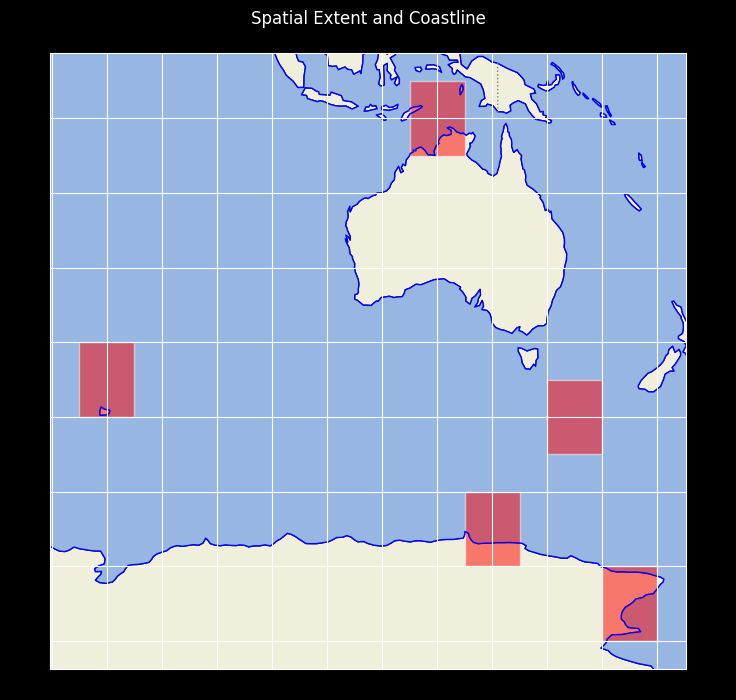

In [6]:
aodn_dataset.plot_spatial_extent()

## Get Temporal Extent of the dataset

Similarly to the spatial extent, we're retrieving the minimum and maximum timestamp partition values of the dataset. This is not necessarily an accurate representation of the TIME values, as the timestamp partition can be yearly, monthly, ..., but it gives an indication of the temporal range.

In [7]:
%%time
aodn_dataset.get_temporal_extent()

CPU times: user 39.6 ms, sys: 9.26 ms, total: 48.9 ms
Wall time: 202 ms


(Timestamp('2018-10-14 14:00:00'), Timestamp('2025-07-02 10:00:00'))

## Read Metadata

For all Parquet datasets, we create a sidecar file named **_common_metadata** in the root of the dataset. This file contains both the dataset-level and variable-level attributes.  
The metadata can be retrieved below as a dictionary, and it will also be included in the pandas DataFrame when using the `get_data` method from the `GetAodn` class.

In [8]:
metadata = aodn_dataset.get_metadata()
metadata

2026-10-14 09:31:18,418 - aodn.GetAodn - INFO - Retrieving metadata for imos-optimised-nonproduction/animal_metadata_satellite_relay_tagging_location_qc_delayed_qc.parquet


{'ptt': {'type': 'int32', 'comment': 'Argos platform terminal transmitter ID'},
 'sex': {'type': 'string', 'comment': 'Animal sex (e.g. m; f; NA)'},
 'body': {'type': 'int32', 'comment': 'SMRU tag ID '},
 'length': {'type': 'double', 'units': 'm', 'comment': 'Animal length (m)'},
 'polygon': {'type': 'string',
  'units': '1',
  'long_name': 'Spatial partition polygon'},
 'species': {'type': 'string', 'comment': 'Deployment animal scientific name'},
 'filename': {'type': 'string',
  'units': '1',
  'long_name': 'Filename of the source file'},
 'tag_type': {'type': 'string', 'comment': 'SMRU tag type designation'},
 'age_class': {'type': 'string',
  'comment': 'Animal age class (e.g. Juvenile; adult; NA)'},
 'device_id': {'type': 'string', 'comment': 'SMRU reference ID '},
 'qc_method': {'type': 'string',
  'comment': 'The approach used to quality control the location data (for IMOS data this is always ArgosQC)'},
 'timestamp': {'type': 'int64',
  'units': '1',
  'long_name': 'Partition 

# Data Query and Plot

## Create a TIME and BoundingBox filter

This cell loads a subset of the dataset based on a time range and a spatial bounding box. The result is returned as a pandas DataFrame, and basic information about its structure is displayed.

In [9]:
%%time
df = aodn_dataset.get_data(date_start='2019-12-01',
                           date_end='2020-10-15',
                           lat_min=-60, lat_max=-50, lon_min=100, lon_max=120)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 28 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   ptt                72 non-null     int32         
 1   sex                72 non-null     object        
 2   body               72 non-null     int32         
 3   length             72 non-null     float64       
 4   species            72 non-null     object        
 5   filename           72 non-null     object        
 6   tag_type           72 non-null     object        
 7   age_class          72 non-null     object        
 8   device_id          72 non-null     object        
 9   qc_method          72 non-null     object        
 10  actual_mass        71 non-null     float64       
 11  common_name        72 non-null     object        
 12  qc_end_date        72 non-null     datetime64[ns]
 13  qc_run_date        72 non-null     object        
 14  release_date

In [10]:
df

,ptt,sex,body,length,species,filename,tag_type,age_class,device_id,qc_method,...,state_country,device_wmo_ref,estimated_mass,qc_proj4string,sattag_program,release_latitude,qc_method_version,release_longitude,timestamp,polygon
0,15208,m,197017,2.13,Mirounga leonina,IMOS_ATF-SATTAG_Location-QC_metadata_ct157_dm.csv,CTD_GEN_18C,subadult,ct157-C208-20,ArgosQC,...,French Overseas Territory,Q9901298,240.0,+proj=stere +lat_0=-90 +lat_ts=-71 +lon_0=100 ...,ct157,-49.36670,0.10.1.9001,70.45000,1575158400,0103000000010000000500000000000000004050400000...
1,15210,m,197015,2.16,Mirounga leonina,IMOS_ATF-SATTAG_Location-QC_metadata_ct157_dm.csv,CTD_GEN_18C,subadult,ct157-C210-20,ArgosQC,...,French Overseas Territory,Q9901299,190.0,+proj=stere +lat_0=-90 +lat_ts=-71 +lon_0=100 ...,ct157,-49.27054,0.10.1.9001,70.54187,1575158400,0103000000010000000500000000000000004050400000...
2,15217,m,197008,2.13,Mirounga leonina,IMOS_ATF-SATTAG_Location-QC_metadata_ct157_dm.csv,CTD_GEN_18C,subadult,ct157-C217-20,ArgosQC,...,French Overseas Territory,Q9901302,230.0,+proj=stere +lat_0=-90 +lat_ts=-71 +lon_0=100 ...,ct157,-49.36670,0.10.1.9001,70.45000,1575158400,0103000000010000000500000000000000004050400000...
3,15220,m,197014,2.23,Mirounga leonina,IMOS_ATF-SATTAG_Location-QC_metadata_ct157_dm.csv,CTD_GEN_18C,subadult,ct157-C220-20,ArgosQC,...,French Overseas Territory,Q9901303,180.0,+proj=stere +lat_0=-90 +lat_ts=-71 +lon_0=100 ...,ct157,-49.27054,0.10.1.9001,70.54187,1575158400,0103000000010000000500000000000000004050400000...
4,15201,m,197024,2.13,Mirounga leonina,IMOS_ATF-SATTAG_Location-QC_metadata_ct157_dm.csv,CTD_GEN_18C,subadult,ct157-C201-20,ArgosQC,...,French Overseas Territory,Q9901294,190.0,+proj=stere +lat_0=-90 +lat_ts=-71 +lon_0=100 ...,ct157,-49.27054,0.10.1.9001,70.54187,1575158400,0103000000010000000500000000000000004050400000...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,10763,f,158104,2.21,Leptonychotes weddellii,IMOS_ATF-SATTAG_Location-QC_metadata_ct156_dm.csv,CTD_GEN_07B,adult,ct156-R763BAT-10,ArgosQC,...,New Zealand Antarctic Territory,Q9901380,NaN,+proj=stere +lat_0=-90 +lat_ts=-71 +lon_0=160 ...,ct156,-77.84953,0.10.1.9001,166.10894,1583020800,0103000000010000000500000000000000000064400000...
68,15227,f,197026,2.24,Leptonychotes weddellii,IMOS_ATF-SATTAG_Location-QC_metadata_ct156_dm.csv,CTD_GEN_20A,adult,ct156-227-VERT-20,ArgosQC,...,New Zealand Antarctic Territory,Q9901381,NaN,+proj=stere +lat_0=-90 +lat_ts=-71 +lon_0=160 ...,ct156,-77.52238,0.10.1.9001,166.25225,1583020800,0103000000010000000500000000000000000064400000...
69,14185,f,158101,2.57,Leptonychotes weddellii,IMOS_ATF-SATTAG_Location-QC_metadata_ct156_dm.csv,CTD_GEN_18C,adult,ct156-185BAT-15,ArgosQC,...,New Zealand Antarctic Territory,Q9901382,NaN,+proj=stere +lat_0=-90 +lat_ts=-71 +lon_0=160 ...,ct156,-77.82878,0.10.1.9001,166.80045,1583020800,0103000000010000000500000000000000000064400000...
70,10881,f,158102,2.51,Leptonychotes weddellii,IMOS_ATF-SATTAG_Location-QC_metadata_ct156_dm.csv,CTD_GEN_07B,adult,ct156-R881BAT-09,ArgosQC,...,New Zealand Antarctic Territory,Q9901383,NaN,+proj=stere +lat_0=-90 +lat_ts=-71 +lon_0=160 ...,ct156,-77.84342,0.10.1.9001,166.62031,1583020800,0103000000010000000500000000000000000064400000...


In [12]:
## Download Subsetted Data as CSV

# This cell downloads the filtered dataset as a ZIP-compressed CSV file.  
# The CSV includes metadata at the top as commented lines, and a `FileLink` object is returned to allow downloading directly from the notebook.


#df.aodn.download_as_csv()